# 03 - Failure analysis

Phase 6: where does the Mini-VLM fail, and does it really use the image? Everything here reads saved predictions
and result files (no training). The only cell that runs a model is the optional ablation at the end, which reads
its saved output instead. Written findings are in `docs/phase6_analysis.md`.

1. Accuracy by question group, against the text-only baseline.
2. How much a no-image question-type prior explains.
3. Counting errors.
4. Annotated failure examples.
5. Image ablation (wrong image, empty image).

In [1]:
import os, sys, json, collections
ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT); os.chdir(ROOT)
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from src.analysis.question_groups import GROUPS, question_group
from src.data.manifest_dataset import read_jsonl
from scripts.analyze_failures import SYSTEMS, group_stats, load_rows

BAR, MUTED, GRID = "#3B6EA8", "#6B6B6B", "#DDDDDD"
def style(ax):
    ax.spines[["top", "right"]].set_visible(False); ax.spines[["left", "bottom"]].set_color(GRID)
    ax.tick_params(colors=MUTED, length=0); ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)

## 1. Accuracy by question group

Each question is put in one group by simple text rules (`src/analysis/question_groups.py`).

In [2]:
stats = {name: group_stats(load_rows(path)) for name, path in SYSTEMS.items()}
cols = GROUPS + ["all"]
print(f"{'system':14s}" + "".join(f"{c:>10s}" for c in cols))
for name in SYSTEMS:
    print(f"{name:14s}" + "".join(f"{stats[name][c]['accuracy']:10.1f}" for c in cols))
print(f"{'n questions':14s}" + "".join(f"{stats['full recipe'][c]['n']:10d}" for c in cols))

system          counting    colour   spatial    yes/no     other       all
text-only           13.2      26.1      12.7      42.8      11.4      24.3
full recipe         43.8      53.6      41.3      79.4      44.2      57.4
ref (reduced)       41.7      38.6      34.4      74.9      40.7      52.2
16 tokens           38.6      38.2      32.7      73.6      35.6      49.4
MLP                 40.0      38.5      30.0      75.4      37.7      50.8
n questions          324       325       216      1056      1079      3000


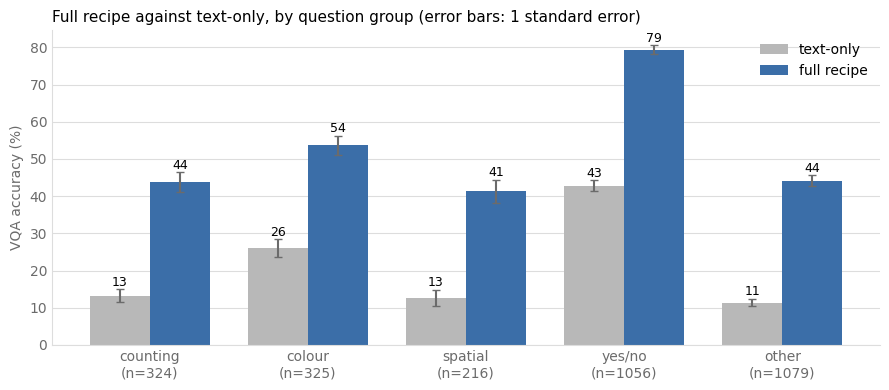

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
w = 0.38; xs = np.arange(len(GROUPS))
for k, (name, color) in enumerate([("text-only", "#B8B8B8"), ("full recipe", BAR)]):
    vals = [stats[name][g]["accuracy"] for g in GROUPS]; errs = [stats[name][g]["se"] for g in GROUPS]
    ax.bar(xs + (k - 0.5) * w, vals, w, color=color, yerr=errs, ecolor=MUTED, capsize=3, label=name)
    for x, v, e in zip(xs + (k - 0.5) * w, vals, errs): ax.text(x, v + e + 1, f"{v:.0f}", ha="center", fontsize=9)
ax.set_xticks(xs); ax.set_xticklabels([f"{g}\n(n={stats['full recipe'][g]['n']})" for g in GROUPS]); ax.set_ylabel("VQA accuracy (%)", color=MUTED)
ax.set_title("Full recipe against text-only, by question group (error bars: 1 standard error)", loc="left", fontsize=11)
ax.legend(frameon=False); style(ax); plt.tight_layout(); plt.show()

Reading: every group gains a lot over text-only. Spatial and counting are the weakest; yes/no looks strong partly because question wording alone already reaches about 43%.

## 2. How much is just the question?

A no-image prior answers each question with the most common training answer for its question type.

group        model  text-only   prior  same as prior
counting      43.8       13.2    34.4            31%
colour        53.6       26.1    24.3            26%
spatial       41.3       12.7     9.7             9%
yes/no        79.4       42.8    66.4            54%
other         44.2       11.4     5.6             7%


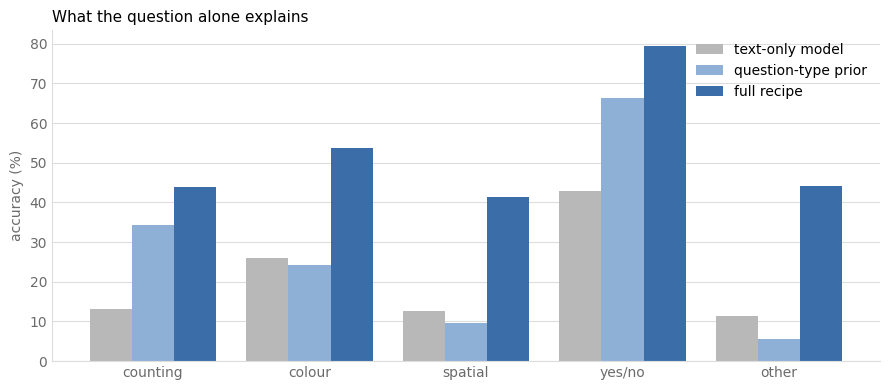

In [4]:
pri = json.load(open("results/failure_analysis/priors.json"))
print(f"{'group':10s}{'model':>8s}{'text-only':>11s}{'prior':>8s}{'same as prior':>15s}")
for g in GROUPS:
    r = pri[g]; print(f"{g:10s}{r['model']:8.1f}{r['text_only']:11.1f}{r['prior']:8.1f}{r['same_as_prior_pct']:14.0f}%")
fig, ax = plt.subplots(figsize=(9, 4))
for k, (key, label, color) in enumerate([("text_only", "text-only model", "#B8B8B8"), ("prior", "question-type prior", "#8FB0D6"), ("model", "full recipe", BAR)]):
    ax.bar(xs + (k - 1) * 0.27, [pri[g][key] for g in GROUPS], 0.27, color=color, label=label)
ax.set_xticks(xs); ax.set_xticklabels(GROUPS); ax.set_ylabel("accuracy (%)", color=MUTED); ax.legend(frameon=False); style(ax)
ax.set_title("What the question alone explains", loc="left", fontsize=11); plt.tight_layout(); plt.show()

Counting and yes/no lean on the prior the most (it alone gets 34% and 66%). Colour, spatial and other questions are mostly out of its reach, so the image is doing the work there.

## 3. Counting errors

321 numeric answers: under-count 148, over-count 54, exact 119


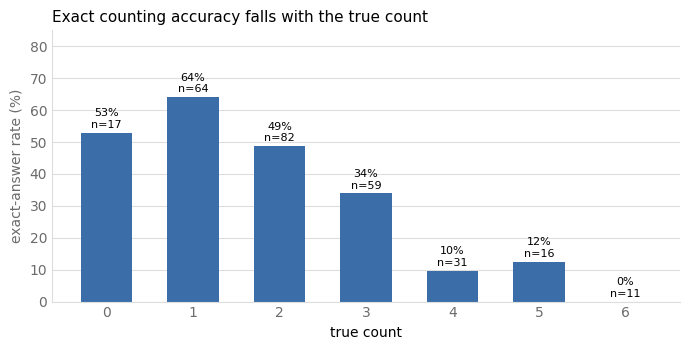

In [5]:
rows = [r for r in load_rows("results/stage2") if question_group(r["question"], r["answer_type"]) == "counting"]
def num(x):
    try: return int(x)
    except ValueError: return None
pairs = [(num(r["answer"]), num(r["cleaned"])) for r in rows]; pairs = [(a, p) for a, p in pairs if a is not None and p is not None]
print(f"{len(pairs)} numeric answers: under-count {sum(p < a for a, p in pairs)}, over-count {sum(p > a for a, p in pairs)}, exact {sum(p == a for a, p in pairs)}")
ks = list(range(0, 7))
exact = [100 * np.mean([p == a for a, p in pairs if a == k]) for k in ks]; cnt = [sum(a == k for a, _ in pairs) for k in ks]
fig, ax = plt.subplots(figsize=(7, 3.6)); ax.bar(ks, exact, 0.6, color=BAR)
for k, v, c in zip(ks, exact, cnt): ax.text(k, v + 1.5, f"{v:.0f}%\nn={c}", ha="center", fontsize=8)
ax.set_xlabel("true count"); ax.set_ylabel("exact-answer rate (%)", color=MUTED); ax.set_ylim(0, 85); style(ax)
ax.set_title("Exact counting accuracy falls with the true count", loc="left", fontsize=11); plt.tight_layout(); plt.show()

## 4. Annotated failure examples

Seeded random failures (soft accuracy 0), 8 per group, drawn by `scripts/failure_examples.py`. Notes below each sheet are my reading of them. The sheets were drawn before the spatial rule was tightened, so two of the "spatial" examples are not position questions.

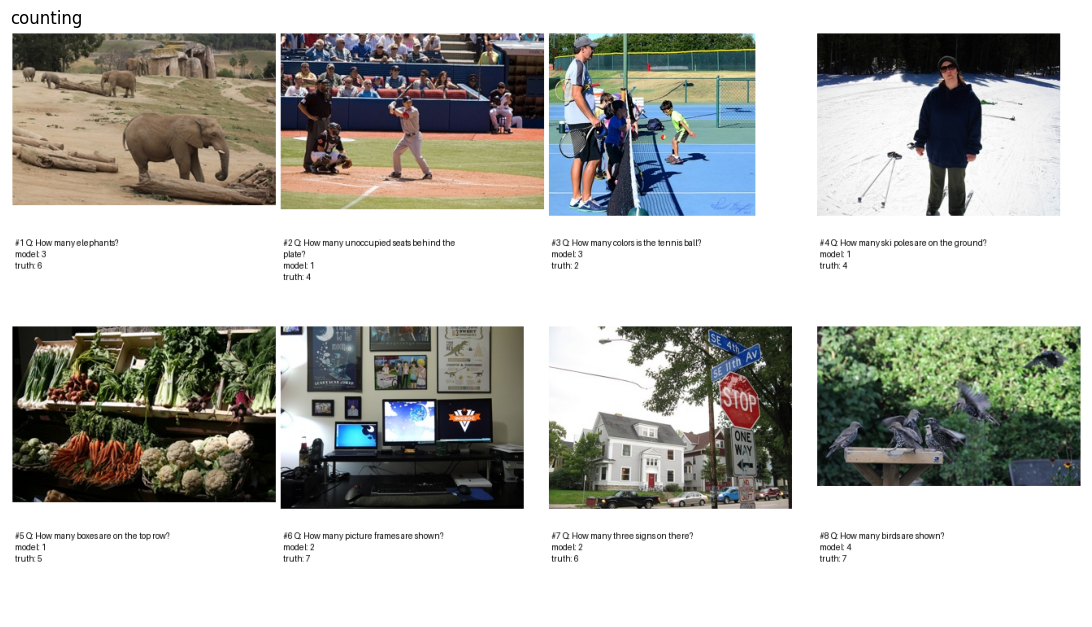

7 of 8 are under-counts of small, thin, partly hidden or numerous objects (elephants 3 vs 6, ski poles 1 vs 4, picture frames 2 vs 7).


In [6]:
def show(group, note):
    img = Image.open(f"results/failure_analysis/examples_{group}.png")
    plt.figure(figsize=(14, 7.6)); plt.imshow(img); plt.axis("off"); plt.title(group, loc="left"); plt.show(); print(note)
show("counting", "7 of 8 are under-counts of small, thin, partly hidden or numerous objects (elephants 3 vs 6, ski poles 1 vs 4, picture frames 2 vs 7).")

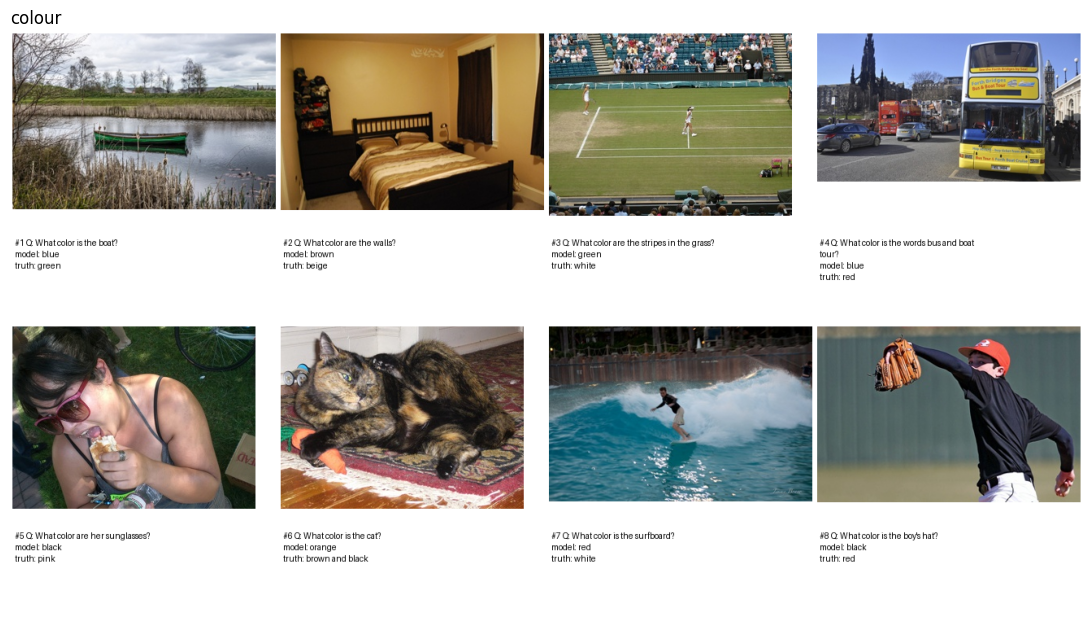

3 of 8 take the colour of a bigger neighbour (boat 'blue' = water, red hat 'black' = shirt, stripes 'green' = grass); others are near shades (brown vs beige) or unexplained.


In [7]:
show("colour", "3 of 8 take the colour of a bigger neighbour (boat 'blue' = water, red hat 'black' = shirt, stripes 'green' = grass); others are near shades (brown vs beige) or unexplained.")

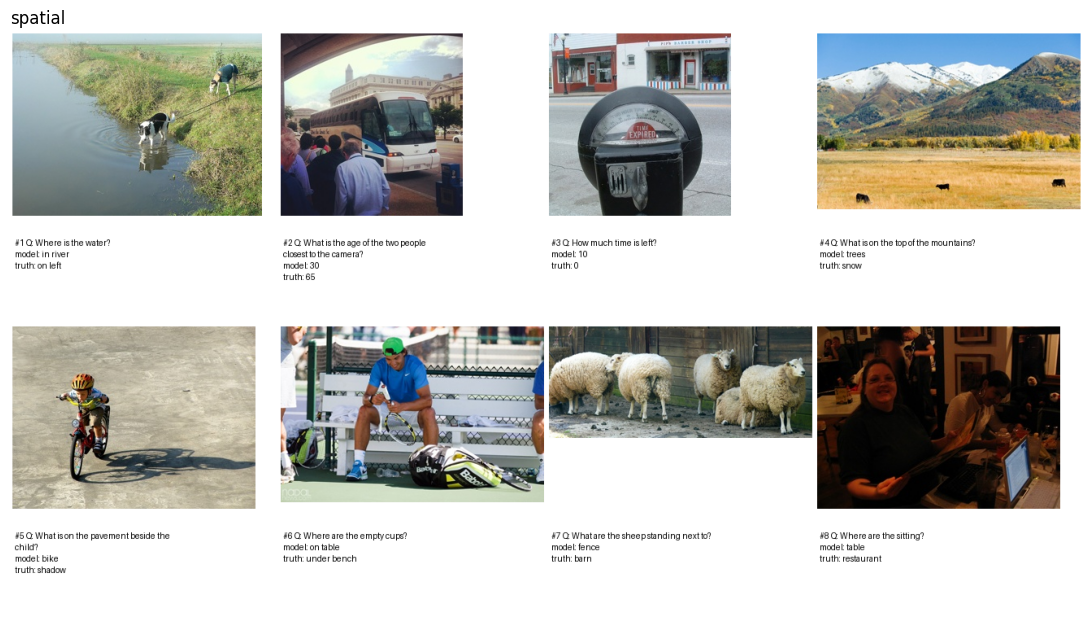

4 of 8 are plausible answers that do not match the written wording (table vs restaurant, fence vs barn); 2 are clear position errors; 2 are not position questions.


In [8]:
show("spatial", "4 of 8 are plausible answers that do not match the written wording (table vs restaurant, fence vs barn); 2 are clear position errors; 2 are not position questions.")

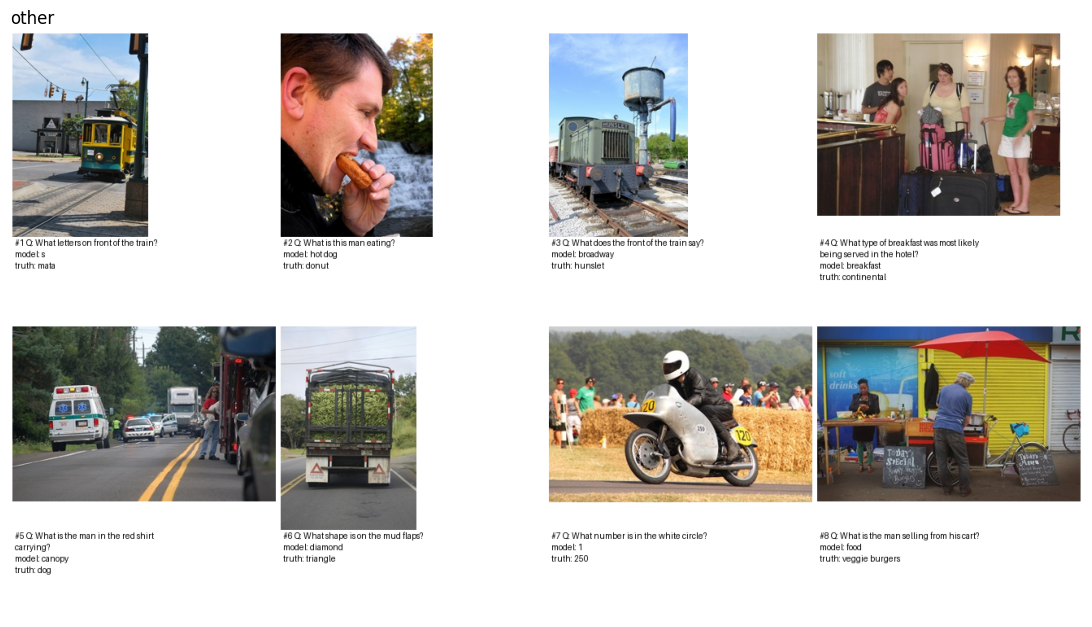

4 of 8 need reading text (train name, a number on a motorbike, a sign): the model invents a plausible word. Others: small objects or fine detail.


In [9]:
show("other", "4 of 8 need reading text (train name, a number on a motorbike, a sign): the model invents a plausible word. Others: small objects or fine detail.")

## 5. Does the model use the image?

The full-recipe model re-answered all 3,000 questions with the image replaced (`scripts/image_ablation.py`; this notebook reads its saved output).

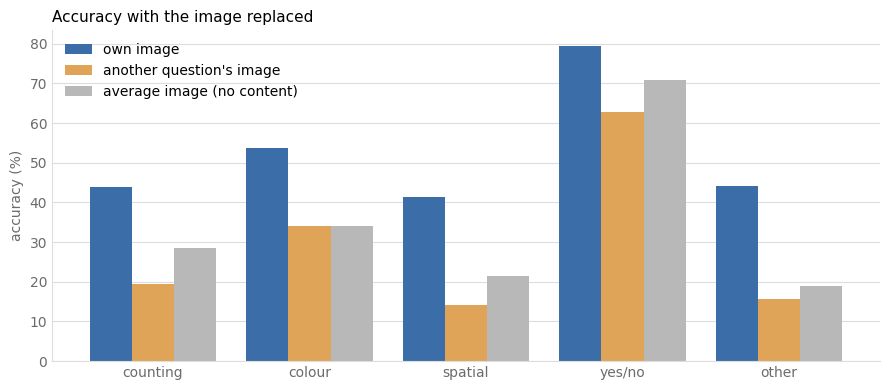

{'real': '57.4', 'other': '34.5', 'mean': '40.1'} | answers changed: other 63%, mean 53%


In [10]:
ab = json.load(open("results/failure_analysis/ablation.json"))
names = {"real": "own image", "other": "another question's image", "mean": "average image (no content)"}
fig, ax = plt.subplots(figsize=(9, 4)); colors = [BAR, "#E0A458", "#B8B8B8"]
for k, key in enumerate(names):
    ax.bar(xs + (k - 1) * 0.27, [ab[key][g] for g in GROUPS], 0.27, color=colors[k], label=names[key])
ax.set_xticks(xs); ax.set_xticklabels(GROUPS); ax.set_ylabel("accuracy (%)", color=MUTED); ax.legend(frameon=False); style(ax)
ax.set_title("Accuracy with the image replaced", loc="left", fontsize=11); plt.tight_layout(); plt.show()
print({k: f"{ab[k]['all']:.1f}" for k in names}, "| answers changed: other", f"{ab['other']['answer_changed_pct']:.0f}%, mean {ab['mean']['answer_changed_pct']:.0f}%")

A wrong image changes 63% of the answers and costs 23 points; an empty image changes 53% and costs 17. A wrong image is worse than none in every group, so the model follows what it sees. For counting, the question-type prior (34%) beats both altered rows, so a wrong image actively misleads.

**Takeaways.** Failures come mostly from small, numerous or hidden objects at 64 tokens, colour taken from a larger neighbour, text that cannot be read at 224 px, and strict answer matching. These are readings of examples, not tested causes. One seed, one model.